# Serie III.3 · Pronósticos de azúcar a uno y tres meses

**Objetivo:** promedio de los cierres diarios publicados del mes calendario objetivo, en centavos de USD/libra. Se pronostica desde el cierre de cada mes a +1 y +3 meses, no un precio físico de Santa Ana ni una rentabilidad de futuros.

La fuente contiene 291 meses completos considerados, marzo de 2000 a mayo de 2024. Junio de 2024 tiene solo 15 observaciones y se conserva aparte; no se usa su promedio parcial como objetivo mensual completo. Los pronósticos finales se emiten **con información al cierre de mayo de 2024**, para junio/agosto de 2024: ejercicio histórico, no cotización ni pronóstico actual.

La continuidad de contratos permanece parcialmente verificada. El objetivo es la referencia publicada del CSV, sin inventar ajustes ni certificar un contrato negociable. [Respuestas centrales](../docs/respuestas-prueba.md), [conclusiones de Serie III](../docs/conclusiones-serie-III.md) y [fuentes](../docs/fuentes-precios/indice.md).

In [1]:
from pathlib import Path
import sys
raiz=Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
if str(raiz) not in sys.path: sys.path.insert(0,str(raiz))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts.pronosticar_azucar_serie3 import ejecutar

decision=ejecutar(raiz)
out=raiz/"outputs/serie3_pronostico"
m=pd.read_csv(out/"mensual.csv")
p=pd.read_csv(out/"predicciones_historicas.csv")
metricas=pd.read_csv(out/"metricas_puntuales.csv")
bandas=pd.read_csv(out/"intervalos_evaluacion.csv")
resumen_bandas=pd.read_csv(out/"metricas_intervalos.csv")
finales=pd.read_csv(out/"pronosticos_ultimo_origen.csv")
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
print(json.dumps(decision,ensure_ascii=False,indent=2))
print("Filas diarias agregadas:",m.n_dias.sum(),"; aparte por mes parcial:",decision["filas_fuera_mes_incompleto"])
display(m.tail(5))

{
  "fuente_sha256": "944471f40adce9a236bc992e3824f8c07f8f87b0f1aa7a5e50c47c888dcd52d1",
  "filas_crudas": 6097,
  "filas_fuera_mes_incompleto": 15,
  "meses_completos": 291,
  "ultimo_origen": "2024-05",
  "objetivo": "promedio mensual de cierres publicados; centavos USD/libra",
  "horizontes_meses": [
    1,
    3
  ],
  "seleccionados": {
    "1": "ingenuo_cierre",
    "3": "ingenuo_cierre"
  },
  "rasgos": [
    "log_cierre_sobre_media",
    "cambio_media_1m",
    "cambio_media_3m"
  ],
  "criterio": "menor complejidad dentro de 2 % de menor MAE en seleccion",
  "seleccion_origenes": [
    "2005-02",
    "2013-09"
  ],
  "calibracion_origenes": [
    "2014-01",
    "2018-09"
  ],
  "evaluacion_origenes_desde": "2019-01",
  "intervalos": "errores de calibracion por horizonte/metodo; cuantiles congelados",
  "continuidad_contratos_certificada": false,
  "pronostico_actual": false,
  "test_nuevo_sin_inspeccion_previa": false
}
Filas diarias agregadas: 6082 ; aparte por mes parcial: 15

,mes,precio,cierre,n_dias,ultimo_dia_observado,n_marcas_calidad,log_cierre_sobre_media,cambio_media_1m,cambio_media_3m
286,2024-01,22.606191,24.129999,21,2024-01-31,0,0.065232,0.017141,-0.174038
287,2024-02,23.355000,22.580000,20,2024-02-29,0,-0.033747,0.032587,-0.156425
288,2024-03,21.731500,22.520000,20,2024-03-28,0,0.035641,-0.072048,-0.022320
289,2024-04,20.647273,19.709999,22,2024-04-30,0,-0.046457,-0.051180,-0.090641
290,2024-05,18.817273,18.299999,22,2024-05-31,0,-0.027874,-0.092808,-0.216036


## Separaci?n temporal y disponibilidad

| Fase | Meses de emisi?n | Uso |
|---|---|---|
| Historia inicial | Marzo 2000?enero 2005 | Entrenamientos; primeros tres meses sin rasgos completos. |
| Selecci?n | Febrero 2005?septiembre 2013 | 104 or?genes por horizonte; elegir m?todo/penalizaci?n. |
| Separaci?n | Octubre?diciembre 2013 | Permitir que todos los objetivos a tres meses de selecci?n maduren antes de calibrar. |
| Calibraci?n | Enero 2014?septiembre 2018 | 57 errores fuera de muestra por m?todo/horizonte para los intervalos. |
| Separaci?n | Octubre?diciembre 2018 | Madurar todos los objetivos de calibraci?n antes de evaluar. |
| Evaluaci?n | Desde enero 2019 | 64 or?genes a un mes y 62 a tres; objetivos disponibles hasta mayo 2024. |

En cada origen reentreno con historia creciente. Una fila de entrenamiento iniciada en j solo entra si **j+h ? origen**; por tanto su promedio mensual objetivo ya est? disponible. Congelo selecci?n y cuantiles de intervalo antes de la evaluaci?n. Incorporar meses ya observados a los entrenamientos posteriores reproduce el uso secuencial y no autoriza usar meses futuros.

La separaci?n es cronol?gica respecto de selecci?n/calibraci?n; inspeccion? la serie completa en el EDA y no presento la evaluaci?n como un periodo nuevo ciego. Los errores a tres meses y las ventanas hist?ricas comparten informaci?n: los casos no son r?plicas independientes.


In [2]:
papeles=pd.read_csv(out/"origenes_y_papeles.csv")
display(papeles.groupby(["horizonte","fase"]).size().rename("meses").reset_index())
display(p.groupby(["fase","horizonte"]).agg(origen_min=("origen","min"),origen_max=("origen","max"),objetivo_max=("objetivo","max"),n=("origen","nunique")))
assert p[p.fase.eq("seleccion")].objetivo.max() < p[p.fase.eq("calibracion")].origen.min()
assert p[p.fase.eq("calibracion")].objetivo.max() < p[p.fase.eq("evaluacion")].origen.min()

,horizonte,fase,meses
0,1,calibracion,57
1,1,evaluacion,64
2,1,historia_inicial,59
3,1,seleccion,104
4,1,separacion_entre_fases,6
5,1,sin_objetivo_completo,1
6,3,calibracion,57
7,3,evaluacion,62
8,3,historia_inicial,59
9,3,seleccion,104


origen_min origen_max objetivo_max    n
fase        horizonte                                        
calibracion 1            2014-01    2018-09      2018-10   57
            3            2014-01    2018-09      2018-12   57
evaluacion  1            2019-01    2024-04      2024-05   64
            3            2019-01    2024-02      2024-05   62
seleccion   1            2005-02    2013-09      2013-10  104
            3            2005-02    2013-09      2013-12  104

## Referencias simples y regresión pequeña

El ingenuo principal repite el **último cierre diario conocido** al emitir el pronóstico. Otra referencia repite el promedio del mes de origen. Comparar solo contra ese promedio retrasado puede hacer parecer útil una regresión que simplemente recupera información del cierre más reciente.

Ridge directo por horizonte utiliza tres rasgos conocidos al origen: log(cierre/promedio del mes), cambio logarítmico del promedio en un mes y en tres meses. Ajusta log(promedio futuro/cierre de origen), con estandarización dentro de cada entrenamiento. Se comparan penalizaciones 1/10/100.

La regla fijada antes de comparar errores elige el método de menor complejidad entre los que quedan a no más de 2 % del menor MAE de selección: primero ingenuo cierre, después ingenuo promedio y luego Ridge con mayor penalización. **El ingenuo cierre se selecciona para ambos horizontes antes de calibración/evaluación.** No se cambian candidatos después de ver la evaluación.

En evaluación, su MAE/WAPE son **0.694 centavos y 3.95 % a un mes**, **1.653 centavos y 9.31 % a tres**. Ridge-100 da 0.703/3.99 % y 1.649/9.29 %: mejora de aproximadamente 0.25 % en MAE a tres meses, insuficiente para justificar complejidad y ausente en selección. WAPE = suma de errores absolutos / suma de precios observados; no es el error porcentual de cada mes.

Las bandas del gráfico corresponden a pronósticos emitidos sucesivamente cada mes. No son una trayectoria completa emitida en enero de 2019.

,fase,horizonte,metodo,n,MAE,RMSE,WAPE_pct,sesgo
0,calibracion,1,ingenuo_cierre,57,0.6876,0.8489,4.5173,-0.0238
1,calibracion,1,ingenuo_media,57,0.9378,1.1955,6.1610,0.0392
4,calibracion,1,ridge_100,57,0.6854,0.8466,4.5027,-0.0307
5,calibracion,3,ingenuo_cierre,57,1.6073,1.9706,10.6636,0.1257
6,calibracion,3,ingenuo_media,57,1.7498,2.1550,11.6088,0.1888
9,calibracion,3,ridge_100,57,1.6362,2.0018,10.8552,0.1918
10,evaluacion,1,ingenuo_cierre,64,0.6942,0.9974,3.9453,-0.0530
11,evaluacion,1,ingenuo_media,64,0.8591,1.2310,4.8828,-0.0959
14,evaluacion,1,ridge_100,64,0.7026,1.0083,3.9930,-0.0358
15,evaluacion,3,ingenuo_cierre,62,1.6527,2.0194,9.3099,-0.3261


Reducción MAE Ridge-100 frente a ingenuo, tres meses (%): 0.2483033589125494


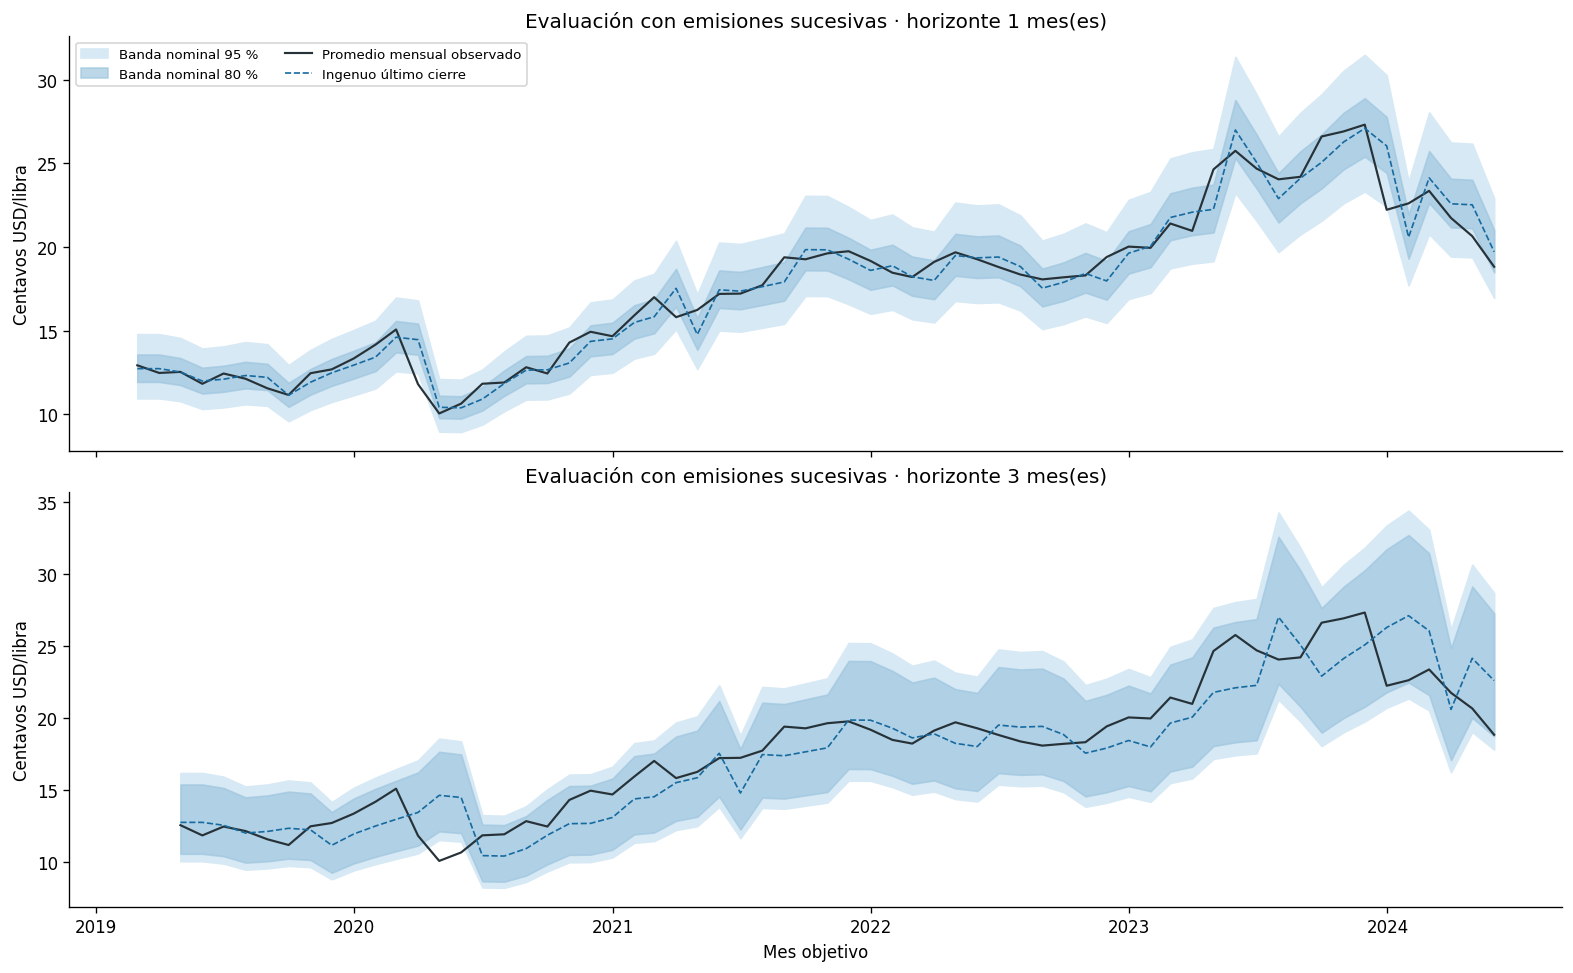

,horizonte,metodo,ano_objetivo,n,MAE,RMSE,WAPE_pct,sesgo
0,1,ingenuo_cierre,2019,11,0.270,0.330,2.191,-0.040
1,1,ingenuo_cierre,2020,12,0.650,0.948,5.047,-0.110
2,1,ingenuo_cierre,2021,12,0.714,0.907,3.999,-0.230
3,1,ingenuo_cierre,2022,12,0.471,0.619,2.503,-0.186
4,1,ingenuo_cierre,2023,12,1.085,1.514,4.510,0.083
5,1,ingenuo_cierre,2024,5,1.283,1.395,5.987,0.473
30,3,ingenuo_cierre,2019,9,0.694,0.881,5.671,-0.050
31,3,ingenuo_cierre,2020,12,2.063,2.310,16.011,-0.398
32,3,ingenuo_cierre,2021,12,1.162,1.449,6.509,-0.980
33,3,ingenuo_cierre,2022,12,0.975,1.068,5.178,-0.163


In [3]:
display(metricas[metricas.metodo.isin(["ingenuo_cierre","ingenuo_media","ridge_100"])].round(4))
comparacion=metricas[metricas.fase.eq("evaluacion") & metricas.horizonte.eq(3)].set_index("metodo")
print("Reducción MAE Ridge-100 frente a ingenuo, tres meses (%):",100*(1-comparacion.loc["ridge_100","MAE"]/comparacion.loc["ingenuo_cierre","MAE"]))
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True,layout="constrained")
for ax,h in zip(axes,[1,3]):
    g=bandas[bandas.metodo.eq("ingenuo_cierre") & bandas.horizonte.eq(h) & bandas.cobertura_nominal.eq(.95)].sort_values("objetivo")
    g80=bandas[bandas.metodo.eq("ingenuo_cierre") & bandas.horizonte.eq(h) & bandas.cobertura_nominal.eq(.8)].sort_values("objetivo")
    fechas=pd.PeriodIndex(g.objetivo,freq="M").to_timestamp(how="end").normalize()
    ax.fill_between(fechas,g.inferior,g.superior,color="#d7e9f4",label="Banda nominal 95 %")
    ax.fill_between(fechas,g80.inferior,g80.superior,color="#9fc6df",alpha=.7,label="Banda nominal 80 %")
    ax.plot(fechas,g.observado,color="#263238",lw=1.3,label="Promedio mensual observado")
    ax.plot(fechas,g.prediccion,color="#176a9f",lw=1,ls="--",label="Ingenuo último cierre")
    ax.set(title=f"Evaluación con emisiones sucesivas · horizonte {h} mes(es)",ylabel="Centavos USD/libra")
axes[0].legend(loc="upper left",fontsize=8,ncol=2)
axes[1].set_xlabel("Mes objetivo")
fig.savefig(out/"evaluacion_pronosticos.png",dpi=160)
plt.show()
display(pd.read_csv(out/"metricas_por_ano.csv").query('metodo == "ingenuo_cierre"').round(3))

## Intervalos: cobertura y amplitud, no solo precisión puntual

Se calibran por método/horizonte los errores absolutos `|ln(observado/predicho)|` de los 57 pronósticos de calibración. Para cobertura nominal c se toma el error ordenado en posición `ceil((n+1)×c)` y se construye `[p×exp(−q), p×exp(q)]`. Las bandas son positivas y reflejan errores de cada horizonte, sin aplicar automáticamente una raíz del tiempo o una distribución normal. Los cuantiles quedan congelados antes de evaluar.

Es una calibración empírica con orden conservador; dependencia, cambios de distribución y n reducido impiden garantizar cobertura futura. A un mes, la banda nominal 80 % cubre **52/64 = 81.25 %**, y la 95 % **62/64 = 96.88 %**. A tres meses ambas cubren **60/62 = 96.77 %**; la del 80 % es conservadora y ancha. Sus incumplimientos coinciden en abril/mayo de 2020, no son dos fallas independientes.

Amplitud media 80/95 %: **2.26/5.29 centavos a un mes y 6.59/8.39 a tres**. Se informa también Winkler: amplitud más penalización por salirse, menor es mejor. Cobertura alta con bandas amplias no demuestra precisión alta.

,horizonte,metodo,cobertura_nominal,n,aciertos,cobertura_real_pct,amplitud_media,Winkler_medio
0,1,ingenuo_cierre,0.80,64,52,81.2500,2.2570,3.5523
1,1,ingenuo_cierre,0.95,64,62,96.8750,5.2880,5.8042
10,3,ingenuo_cierre,0.80,62,60,96.7742,6.5908,7.1384
11,3,ingenuo_cierre,0.95,62,60,96.7742,8.3947,9.8183


,horizonte,metodo,cobertura_nominal,n_calibracion,orden,q_log,ultimo_objetivo_calibracion
0,1,ingenuo_cierre,0.80,57,47,0.064290,2018-10
1,1,ingenuo_cierre,0.95,57,56,0.150162,2018-10
10,3,ingenuo_cierre,0.80,57,47,0.187996,2018-12
11,3,ingenuo_cierre,0.95,57,56,0.238594,2018-12


,origen,objetivo,horizonte,observado,inferior,superior
77,2020-02,2020-03,1,11.805000,12.443817,16.802851
122,2023-11,2023-12,1,22.222000,22.409198,30.259076
714,2020-01,2020-04,3,10.051905,11.508803,18.546854
715,2020-02,2020-05,3,10.641000,11.390643,18.356435


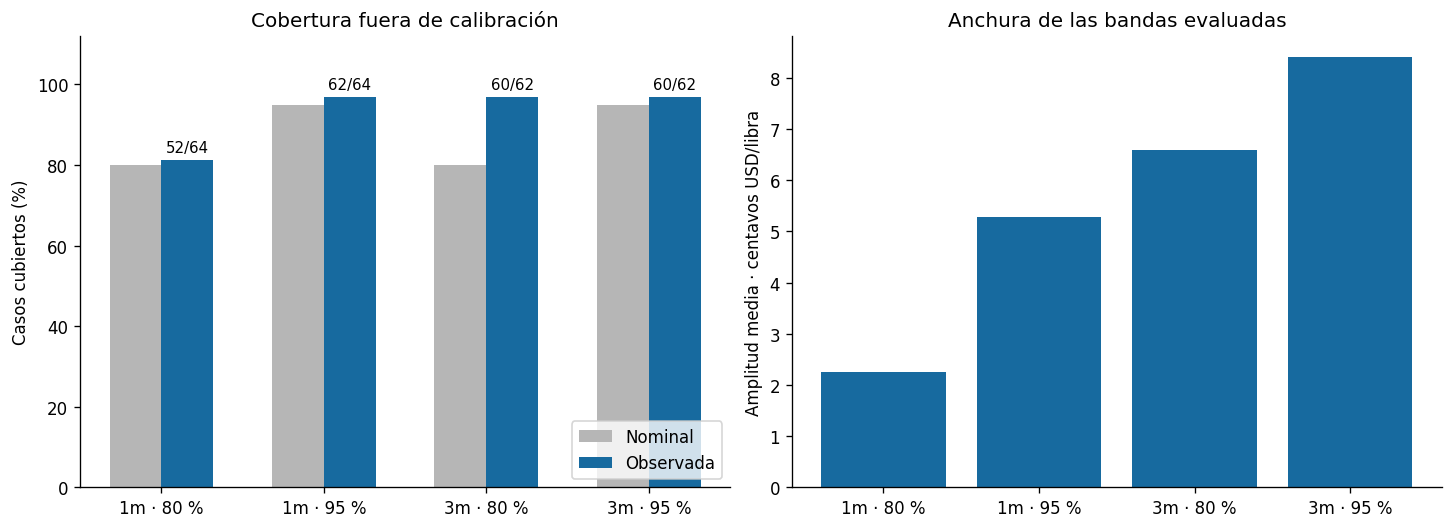

In [4]:
g=resumen_bandas[resumen_bandas.metodo.eq("ingenuo_cierre")].sort_values(["horizonte","cobertura_nominal"]).copy()
display(g.round(4))
display(pd.read_csv(out/"cuantiles_calibracion.csv").query('metodo == "ingenuo_cierre"').round(6))
display(bandas[bandas.metodo.eq("ingenuo_cierre") & bandas.cobertura_nominal.eq(.95) & ~bandas.cubierto][["origen","objetivo","horizonte","observado","inferior","superior"]])
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout="constrained")
x=np.arange(len(g)); etiquetas=[f"{h}m · {int(c*100)} %" for h,c in zip(g.horizonte,g.cobertura_nominal)]
axes[0].bar(x-.16,g.cobertura_nominal*100,width=.32,color="#b6b6b6",label="Nominal")
axes[0].bar(x+.16,g.cobertura_real_pct,width=.32,color="#176a9f",label="Observada")
for xx,aciertos,nn,yy in zip(x,g.aciertos,g.n,g.cobertura_real_pct):
    axes[0].text(xx+.16,yy+2,f"{aciertos}/{nn}",ha="center",fontsize=9)
axes[0].set(title="Cobertura fuera de calibración",ylabel="Casos cubiertos (%)",ylim=(0,112),xticks=x,xticklabels=etiquetas)
axes[0].legend(loc="lower right")
axes[1].bar(x,g.amplitud_media,color="#176a9f")
axes[1].set(title="Anchura de las bandas evaluadas",ylabel="Amplitud media · centavos USD/libra",xticks=x,xticklabels=etiquetas)
fig.savefig(out/"cobertura_y_amplitud.png",dpi=160)
plt.show()

## Pron?stico del ?ltimo origen completo

Emisi?n hist?rica al cierre de **mayo de 2024**, con ?ltimo cierre 18.30 centavos/libra. El punto es el mismo a ambos horizontes porque el m?todo elegido persiste ese cierre; la incertidumbre aumenta con el horizonte.

| Mes objetivo | Punto | Banda nominal 80 % | Banda nominal 95 % |
|---|---:|---|---|
| Junio 2024 (+1) | 18.30 | 17.16?19.52 | 15.75?21.27 |
| Agosto 2024 (+3) | 18.30 | 15.16?22.08 | 14.42?23.23 |

No incorporo junio parcial a este origen ni completo artificialmente su precio observado. El gr?fico solo muestra los dos horizontes requeridos, sin inventar un pron?stico de julio.

En la sensibilidad que eval?a solo emisiones/objetivos sin marcas directas de OHLC/volumen cero, permanecen 47 casos a un mes y 42 a tres. WAPE ingenuo 3.42 % y 8.11 %; Ridge-100 no lo mejora en esa vista. No es una muestra certificada sin enlaces: las marcas no identifican todos los vencimientos ni prueban la calidad de los dem?s meses.


,origen,objetivo,horizonte,metodo,seleccionado,prediccion,inferior_80,superior_80,inferior_95,superior_95
0,2024-05,2024-06,1,ingenuo_cierre,True,18.3,17.1605,19.5151,15.7484,21.2650
5,2024-05,2024-08,3,ingenuo_cierre,True,18.3,15.1637,22.0850,14.4155,23.2312


,horizonte,metodo,n,MAE,RMSE,WAPE_pct,sesgo
0,1,ingenuo_cierre,47,0.5898,0.7733,3.4221,-0.1091
4,1,ridge_100,47,0.5983,0.7853,3.4709,-0.0853
5,3,ingenuo_cierre,42,1.3713,1.6856,8.1108,-0.4054
9,3,ridge_100,42,1.3736,1.7040,8.1239,-0.3343


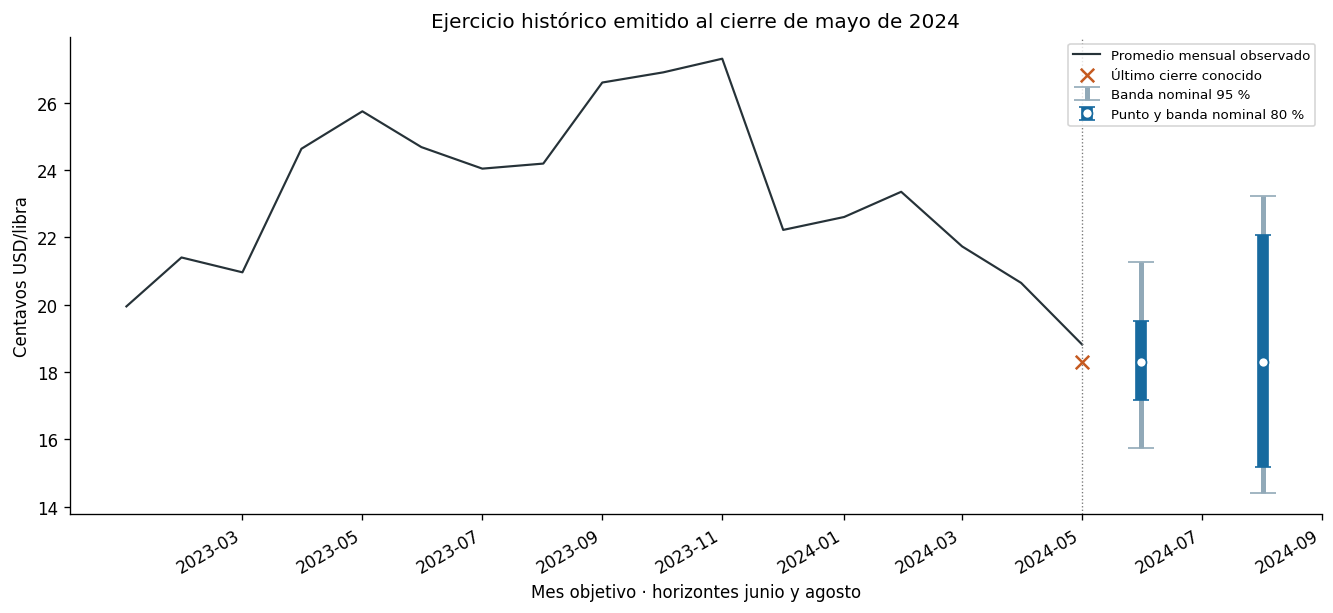

In [5]:
elegidos=finales[finales.seleccionado].sort_values("horizonte")
display(elegidos.round(4))
display(pd.read_csv(out/"sensibilidad_calidad.csv").query('metodo in ["ingenuo_cierre","ridge_100"]').round(4))
fig,ax=plt.subplots(figsize=(11,5),layout="constrained")
hist=m[m.mes.ge("2023-01")]
fechas=pd.PeriodIndex(hist.mes,freq="M").to_timestamp(how="end").normalize()
ax.plot(fechas,hist.precio,color="#263238",label="Promedio mensual observado",lw=1.3)
fecha_origen=pd.Period("2024-05","M").to_timestamp(how="end").normalize()
ax.scatter([fecha_origen],[m.cierre.iloc[-1]],marker="x",s=65,color="#c55a20",label="Último cierre conocido",zorder=5)
fechas_futuras=pd.PeriodIndex(elegidos.objetivo,freq="M").to_timestamp(how="end").normalize()
ax.errorbar(fechas_futuras,elegidos.prediccion,yerr=np.array([elegidos.prediccion-elegidos.inferior_95,elegidos.superior_95-elegidos.prediccion]),fmt="none",ecolor="#91a9b8",elinewidth=3,capsize=8,label="Banda nominal 95 %")
ax.errorbar(fechas_futuras,elegidos.prediccion,yerr=np.array([elegidos.prediccion-elegidos.inferior_80,elegidos.superior_80-elegidos.prediccion]),fmt="o",mfc="white",mec="#176a9f",ms=6,color="#176a9f",elinewidth=7,capsize=5,label="Punto y banda nominal 80 %")
ax.axvline(fecha_origen,color="#777777",ls=":",lw=.8)
ax.set(title="Ejercicio histórico emitido al cierre de mayo de 2024",ylabel="Centavos USD/libra",xlabel="Mes objetivo · horizontes junio y agosto")
ticks=pd.period_range("2023-02","2024-08",freq="2M").to_timestamp(how="end").normalize()
ax.set_xticks(ticks,[d.strftime("%Y-%m") for d in ticks],rotation=30,ha="right")
ax.legend(loc="upper right",fontsize=8)
fig.savefig(out/"pronostico_ultimo_origen.png",dpi=160)
plt.show()

## Conclusión y evaluación gerencial

**Resultado:** el ingenuo del último cierre es la solución elegida por selección temporal. Ridge no demuestra valor adicional suficiente con los tres rasgos y penalizaciones estudiados. Esto no prueba que ningún modelo pueda mejorar el pronóstico; evita añadir complejidad sin evidencia en este experimento.

**Utilidad:** adoptar la referencia sencilla con bandas para presupuesto y contrastar decisiones con escenarios adversos. Este contraste se limita a Ridge de tres rasgos. El [notebook 18](18_pronostico_ampliado_serie3.ipynb) compara otras familias y hasta 24 variables: propongo Extra Trees a un mes y Ridge histórico a tres meses, con mejoras posteriores de MAE de 6.12 % y 1.35 %. La elección es exploratoria; no hay test ciego reservado y la confirmación con datos no utilizados está pendiente. El ingenuo conserva su papel de baseline y ganador de la selección anterior. A tres meses el mayor error y las bandas amplias favorecen evaluar decisiones que resistan distintos precios.

**Límites:** fuente continua sin linaje certificado, posible mezcla de contratos, objetivo distinto de liquidación de un vencimiento y del precio físico recibido, muestras pequeñas/dependientes y calibración de un periodo que no garantiza riesgos posteriores. No se estima beneficio comercial, coste de cobertura ni causalidad. Las cifras finales son un ejercicio con datos hasta 2024, no una recomendación para operar hoy.

**Verificación:** seis pruebas específicas reconstruyen agregación, los pronósticos por ecuación matricial, maduración de etiquetas, selección, cuantiles, cobertura y Winkler. Cambiar datos futuros no altera los pronósticos anteriores; modificar calibración/evaluación no modifica la elección del modelo. Conservo fuente, 15 filas del mes parcial y papeles de todos los orígenes. Las pruebas comprueban implementación, sin certificar todos los precios ni una cobertura futura.

Evidencia: `outputs/serie3_pronostico/`, incluida la decisión, tablas por fase/año/calidad, predicciones por origen, bandas, parámetros de ajustes, trazabilidad de exclusiones y artefacto seleccionado. Los cuatro incisos tienen respuesta analítica con límites; el [notebook 17](17_oferta_precio_serie3.ipynb) examina oferta/precio y rezagos sin identificación causal.

El [fundamento económico y las decisiones de Serie III](../docs/conclusiones-serie-III.md#lectura-económica-y-decisiones) integra evidencia, teoría, recomendaciones y sus supuestos.